# Avaliação no split de teste

Avalia o checkpoint treinado no split de teste (nunca visto em treino/validação), reportando top-1/top-2, macro-F1, matriz de confusão e acurácia por grupo de Denver. Salva as probabilidades softmax do teste, usadas depois na Fase 5.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src" / "classification"))
sys.path.insert(0, str(REPO_ROOT / "src" / "preprocessing"))

from evaluate import evaluate

CHECKPOINT = Path("../runs/resnet50-30epochs/best.pt")  # ajustar pro run treinado em 02_train.ipynb
metrics = evaluate(CHECKPOINT)


Top-1: 0.9822  Top-2: 0.9929  Macro-F1: 0.9815
Acurácia por grupo de Denver:
  A: 0.9973
  B: 0.9833
  C: 0.9877
  D: 0.9873
  E: 0.9871
  F: 0.9800
  G: 0.9783
  X: 0.9765
  Y: 0.9679
Probabilidades salvas em: ../runs/resnet50-30epochs/test_probs.npy


Matriz de confusão 24x24 -- erros esperados se concentram dentro do mesmo grupo de Denver (classes de tamanho parecido: C6-C12, D13-D15, F19/F20, G21/G22).

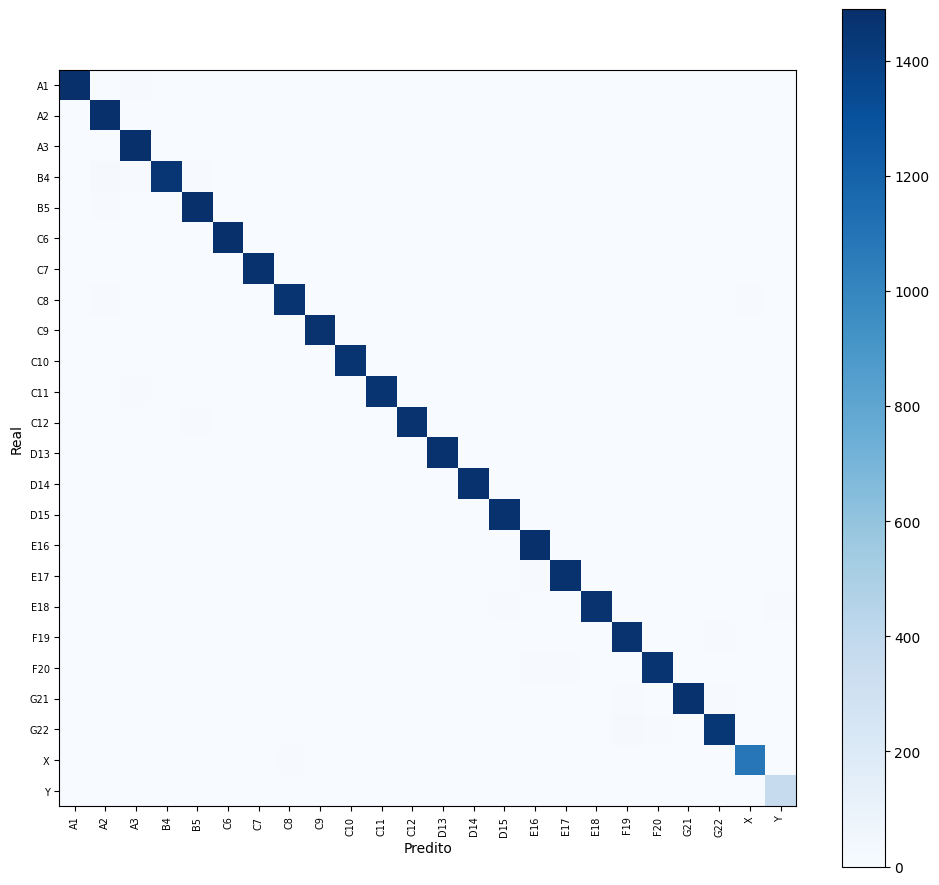

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from voc_to_yolo import DENVER_CLASSES

cm = np.array(metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(DENVER_CLASSES)))
ax.set_yticks(range(len(DENVER_CLASSES)))
ax.set_xticklabels(DENVER_CLASSES, rotation=90, fontsize=7)
ax.set_yticklabels(DENVER_CLASSES, fontsize=7)
ax.set_xlabel("Predito")
ax.set_ylabel("Real")
fig.colorbar(im)
plt.tight_layout()
plt.show()
